In [1]:
from platform import python_version

print(python_version())

3.13.9


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('default') #sets clean style
#%matplotlib inline 
#renders plots in noteboox

from pathlib import Path
import numpy as np

#for plots
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
import seaborn as sns
import math

In [3]:
import os 

cwd = os.getcwd() 
print("Current Working Directory:", cwd)

Current Working Directory: /Users/jenniferbadger


In [4]:
os.chdir('/Users/jenniferbadger/Jenniferbethbadger Dropbox/Kern County Team/Georeferencing/tables')

print("Current Working Directory", os.getcwd())

Current Working Directory /Users/jenniferbadger/Jenniferbethbadger Dropbox/Kern County Team/Georeferencing/tables


In [158]:
crops_58 = Path("Crops_58_merged.csv")

print(crops_58.name)

Crops_58_merged.csv


In [159]:
crops_58 = pd.read_csv(crops_58) 
crops_58.head(10)

,Code,Crop_category,Crop_type,Irrigation_status,Land_cover,Notes,Shape_Area_acres,Shape_Length,Shape_Area
0,iT12,T,Potatoes,i,NaN,NaN,23.146757,4021.006307,1.008270e+06
1,iF1,F,Cotton,i,NaN,NaN,118.228668,10694.515455,5.150028e+06
2,iV,V,Grapes,i,NaN,unknown subclass,15.170734,3337.970548,6.608355e+05
3,<Null>,<Null>,<Null>,<Null>,Unknown,<Null>,8.638550,2919.197247,3.762943e+05
4,iV,V,Grapes,i,NaN,unknown subclass,45.299418,7030.232033,1.973238e+06
5,iVY,V,Grapes,i,NaN,young non-bearing,12.493871,3387.485363,5.442316e+05
6,iF1,F,Cotton,i,NaN,NaN,20.768798,3808.566932,9.046865e+05
7,iT12,T,Potatoes,i,NaN,NaN,20.596186,3792.528171,8.971676e+05
8,iF1,F,Cotton,i,NaN,NaN,7.653695,2650.429778,3.333941e+05
9,iT12,T,Potatoes,i,NaN,NaN,8.449539,2719.020068,3.680610e+05


In [160]:
data58 = crops_58["Shape_Area_acres"] 

# Sample statistics
mean58 = np.mean(data58)
std_err58 = stats.sem(data58)  # Standard error of the mean

# 95% confidence interval
ci58 = stats.t.interval(confidence=0.95, df=len(data58)-1, loc=mean58, scale=std_err58)

print(f"mean: {mean58}", f"std_error: {std_err58}", f"95% confidence interval: {ci58}")

mean: 59.92292901661408 std_error: 1.7811025485412646 95% confidence interval: (np.float64(56.43012357779316), np.float64(63.41573445543499))


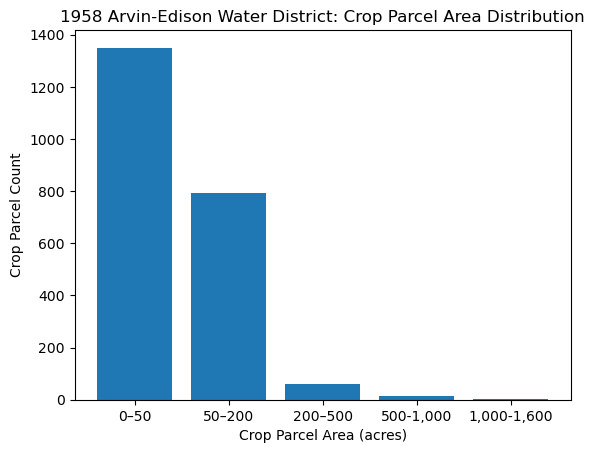

In [161]:
#dropping NAs
#crops_58["Shape_Area_acres"] = pd.to_numeric(crops_58["Shape_Area_acres"], errors="coerce")
crops_58 = crops_58.dropna(subset=["Shape_Area_acres"])

# binning to match maps
bins = [0, 50, 200, 500, 1000, 1600]
labels = ["0–50", "50–200", "200–500","500-1,000", "1,000-1,600"]

# classify
crops_58["acres_bin"] = pd.cut(crops_58["Shape_Area_acres"], bins=bins, labels=labels, include_lowest=True)

# count
counts58 = crops_58["acres_bin"].value_counts().sort_index()

# plot
plt.bar(counts58.index.astype(str), counts58.values)
plt.xlabel("Crop Parcel Area (acres)")
plt.ylabel("Crop Parcel Count")
plt.title("1958 Arvin-Edison Water District: Crop Parcel Area Distribution")

plt.show()

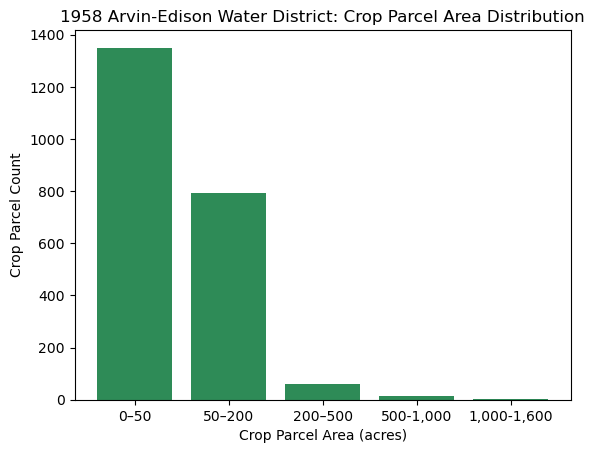

In [162]:
# plot
plt.bar(counts58.index.astype(str), counts58.values, 
        color = "seagreen")
plt.xlabel("Crop Parcel Area (acres)")
plt.ylabel("Crop Parcel Count")
plt.title("1958 Arvin-Edison Water District: Crop Parcel Area Distribution")

plt.savefig('1958_acres.png')
plt.show()


In [150]:
crops_70 = Path("Crops_70_merged2.csv")

print(crops_70.name)

Crops_70_merged2.csv


In [151]:
crops_70 = pd.read_csv(crops_70) 
crops_70.head(10)

,code,Crop_categ,Crop_type,Irrigation,Land_cover,Notes,Shape_Leng,Shape_Area_acres,Shape_Length,Shape_Area
0,"T3-b, T3-c",T,Beans,i,,,6950.275966,50.177812,6950.275966,2.185740e+06
1,F1,F,Cotton,i,,,43448.164010,462.616281,32687.680429,2.015151e+07
2,V,V,Vineyards,i,,,5178.037796,31.341652,5178.037796,1.365239e+06
3,D,D,Deciduous fruits & nuts,i,,,12243.041534,92.370552,12243.041534,4.023651e+06
4,G,G,Grain and hay,i,,,8561.060331,97.321265,8561.060331,4.239303e+06
5,G,G,Grain and hay,i,,,4058.428588,15.947722,4058.428588,6.946810e+05
6,TF,TF,Diversified,i,,,7080.949431,69.114650,7080.949431,3.010626e+06
7,P1S,P,Alfalfa & alfalfa mixtures,i,,Seed crop,4145.618263,21.961464,4145.618263,9.566389e+05
8,F1,F,Cotton,i,,,3657.468824,14.279760,3657.468824,6.220247e+05
9,G,G,Grain and hay,i,,,6954.013255,49.120522,6954.013255,2.139684e+06


In [152]:
len(crops_70)

1498

In [153]:
crops_70["Shape_Area_acres"].mean()

np.float64(85.81032671338035)

In [154]:
import scipy.stats as stats
data70 = crops_70["Shape_Area_acres"] 

# Sample statistics
mean = np.mean(data70)
std_err = stats.sem(data70)  # Standard error of the mean

# 95% confidence interval
ci = stats.t.interval(confidence=0.95, df=len(data70)-1, loc=mean, scale=std_err)

print(f"mean: {mean}", f"std_error: {std_err}", f"95% confidence interval: {ci}")

mean: 85.81032671338035 std_error: 5.303395090459734 95% confidence interval: (np.float64(75.40745245394518), np.float64(96.21320097281551))


In [155]:
#dropping NAs
#crops_70["Shape_Area_acres"] = pd.to_numeric(crops_58["Shape_Area_acres"], errors="coerce")
crops_70 = crops_70.dropna(subset=["Shape_Area_acres"])

# binning to match maps
bins = [0, 50, 200, 500, 1000, 4600]
labels = ["0–50", "50–200", "200–500","500-1,000", "1,000-4,600"]

# classify
crops_70["acres_bin"] = pd.cut(crops_70["Shape_Area_acres"], bins=bins, labels=labels, include_lowest=True)

counts70 = crops_70["acres_bin"].value_counts().sort_index()

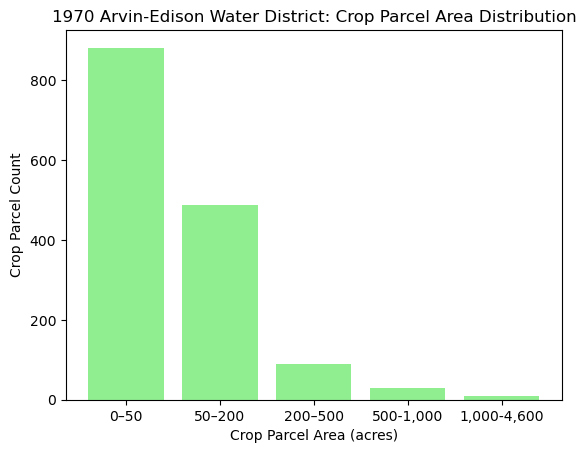

In [156]:
# plot
plt.bar(counts70.index.astype(str), counts70.values, 
        color = "lightgreen")

#plt.ylim(top=1400)
plt.xlabel("Crop Parcel Area (acres)")
plt.ylabel("Crop Parcel Count")
plt.title("1970 Arvin-Edison Water District: Crop Parcel Area Distribution")

plt.savefig('1970_acres.png')
plt.show()


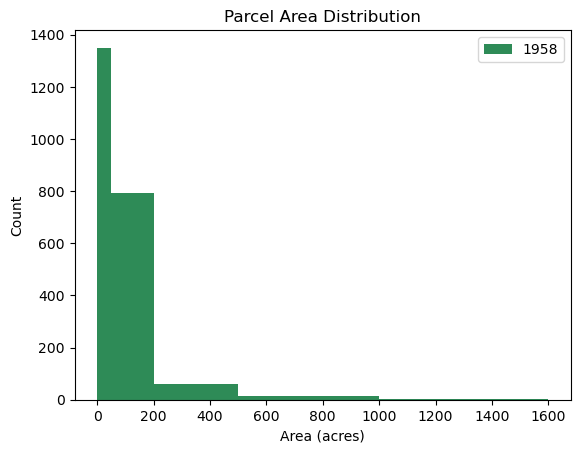

In [115]:
import matplotlib.pyplot as plt

# bins
bins = [0, 50, 200, 500, 1000, 1600]

plt.hist(
    [crops_58["Shape_Area_acres"]],
    color = "seagreen",
    bins=bins,
    label=["1958"]
)

plt.legend()
plt.xlabel("Area (acres)")
plt.ylabel("Count")
plt.title("Parcel Area Distribution")

plt.show()

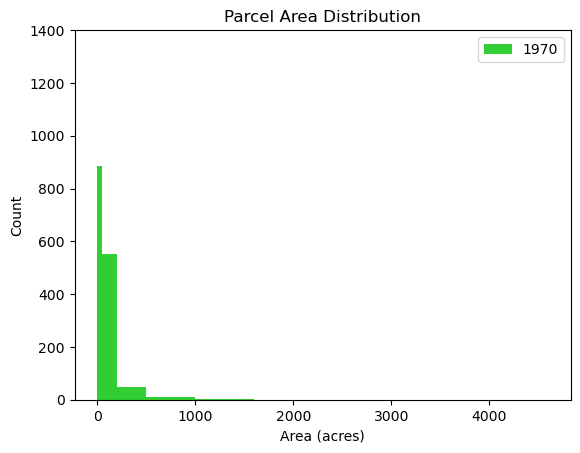

In [116]:
# bins
bins = [0, 50, 200, 500, 1000, 1600, 4600]

plt.hist(
    [crops_70["Shape_Area_acres"]],
    color = "limegreen",
    bins=bins,
    label=["1970"],
     
)

plt.legend()
plt.ylim(top=1400)
plt.xlabel("Area (acres)")
plt.ylabel("Count")
plt.title("Parcel Area Distribution")

plt.show()

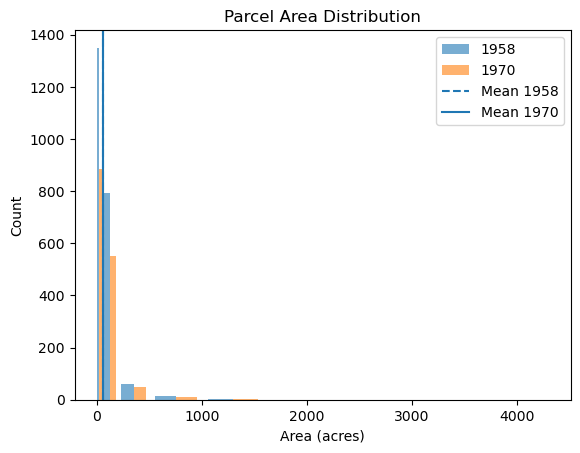

In [117]:
mean_58 = crops_58["Shape_Area_acres"].mean()
mean_70 = crops_70["Shape_Area_acres"].mean()

plt.hist(
    [crops_58["Shape_Area_acres"], crops_70["Shape_Area_acres"]],
    bins=bins,
    alpha=0.6,
    label=["1958", "1970"]
)

# mean lines
plt.axvline(mean_58, linestyle="--", label="Mean 1958")
plt.axvline(mean_70, linestyle="-", label="Mean 1970")

plt.legend()
plt.xlabel("Area (acres)")
plt.ylabel("Count")
plt.title("Parcel Area Distribution")

plt.show()

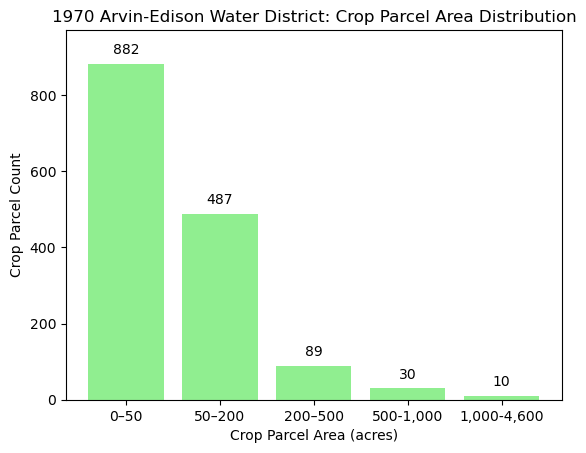

In [157]:
fig, ax = plt.subplots()

bars = ax.bar(counts70.index.astype(str),
              counts70.values,
              color="lightgreen")

_ = ax.bar_label(bars, padding=5)

ax.set_ylim(0, max(counts70.values) * 1.1)

plt.xlabel("Crop Parcel Area (acres)")
plt.ylabel("Crop Parcel Count")
plt.title("1970 Arvin-Edison Water District: Crop Parcel Area Distribution")

plt.savefig('1970_acres.png')

plt.show()

plt.show()

In [121]:
crops_70["Shape_Area_acres"].mean()

np.float64(63.174598850966376)

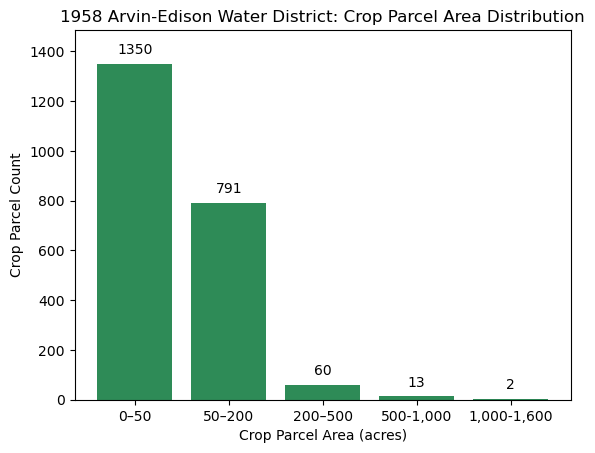

In [163]:
fig, ax = plt.subplots()

bars = ax.bar(counts58.index.astype(str),
              counts58.values,
              color="seagreen")

_ = ax.bar_label(bars, padding=5)

ax.set_ylim(0, max(counts58.values) * 1.1)

plt.xlabel("Crop Parcel Area (acres)")
plt.ylabel("Crop Parcel Count")
plt.title("1958 Arvin-Edison Water District: Crop Parcel Area Distribution")

plt.savefig('1958_acres.png')

plt.show()

In [128]:
crops_58["Shape_Area_acres"].mean()

np.float64(59.92292901661408)